# Group Leakage Simulation: Why a great validation score can fail in production

Oftentimes, I hear in data science that a model with a *high and stable validation score is ready for production*. In my experience, this depends on **validated against what exactly?** A random train/test split tells us how well the model predicts rows that look like the ones it has already seen. However, this is half the story; if the same entity appears in both the training and the test set, the model can memorize the entity instead of learning the pattern, and no amount of extra data will reveal it. In this notebook, I will simulate a data-generating process and show this point.

For the sake of this example, I will simulate transactions on a marketplace app, where the goal is to classify whether a transaction is fraudulent. Transactions are nested within sellers, and each seller $s$ carries a latent fraud risk that the platform never observes directly:

**Seller level** ($s = 1, \dots, S$):
$$
u_s \sim N(0, 2.5)
$$$$
\text{AccountAge}_s = \exp\big(5 - 0.3\cdot u_s + \eta_s\big), \quad \eta_s \sim N(0, 1.2)
$$$$
\text{Rating}_s = \min\big(5, \max(1,\; 4.3 - 0.15\cdot u_s + \nu_s)\big), \quad \nu_s \sim N(0, 0.8)
$$

**Transaction level** ($i = 1, \dots, 50$ transactions per seller):
$$
\text{OrderValue}_i = \exp(\omega_i), \quad \omega_i \sim N(4, 0.8)
$$$$
\text{DeviceMismatch}_i \sim \text{Bernoulli}(0.15)
$$$$
\text{ShipDistance}_i \sim \text{Exponential}(\text{mean} = 300)
$$$$
\text{Fraud}_i \sim \text{Bernoulli}\big(p_i\big), \quad p_i = \text{logit}^{-1}\Big(-5.5 + 0.3\cdot\tfrac{\ln(\text{OrderValue}_i) - 4}{0.8} + 0.6\cdot\text{DeviceMismatch}_i + 0.3\cdot\tfrac{\text{ShipDistance}_i}{300} + u_{s(i)}\Big)
$$

where $\text{logit}^{-1}(x) = \frac{1}{1+e^{-x}}$, $s(i)$ is the seller who processed transaction $i$, and the second argument of each normal distribution is the standard deviation. This yields a fraud base rate of roughly 5%.

Two features of this setup matter. First, most of the fraud risk lives at the seller level: on the latent scale, the seller effect $u_s$ accounts for roughly 97% of the variance, which mirrors how fraud tends to cluster in bad-actor accounts. Second, account age and rating do not enter the fraud equation directly. They are deliberately noisy proxies of $u_s$: riskier sellers tend to have newer accounts and lower ratings, but the platform can only see these weak signals, never $u_s$ itself.

This creates the trap. If we include `seller_id` as a feature (target encoded) and evaluate with a random train/test split, the same sellers appear on both sides of the split. The model learns each seller's fraud rate directly, the proxies look redundant next to it, and the validation AUC looks excellent. In production, however, the question is whether a **new** seller's transaction is fraudulent, and for a new seller, `seller_id` carries no information at all.

I will compare three approaches, each evaluated on a fresh set of sellers the model has never seen, alongside the validation score each one would have reported:

1. **Leaky model:** logistic regression on the transaction features plus target-encoded `seller_id`, validated with a random split.
2. **Right model:** logistic regression on the transaction features plus account age and rating, validated with a split by seller.
3. **Red-flag heuristic:** count how many of these hold: account age under 60 days, rating below 4.0, order value above \$150 (roughly the top decile), and a device mismatch. The thresholds are fixed beforehand from domain priors, never tuned on the labels, so the heuristic has no leakage of its own.

## Let's simulate this data

I will create a function to do this because it will come in handy later when testing it in production

In [1]:
import numpy as np
import pandas as pd

In [2]:
#Seller Level Data (I will only touch the number so all other parameters will remain fixed)
def simulate_seller(n_s,id_start=1):
 umean, usd = (0,2.5 )
 etamean, etasd = (0,1.2)
 vmean, vusd = (0,0.8)
 data = pd.DataFrame({
     'u_s':np.random.normal(umean,usd,n_s),
     'eta_s':np.random.normal(etamean,etasd,n_s),
     'v_s':np.random.normal(vmean,vusd,n_s)
 })
 data['age'] = np.exp(5-0.3*data['u_s']+data['eta_s'])
 data['ln_age'] = np.log(data['age'] )
 data['rating'] = np.minimum(5,np.maximum(1, 4.3 - 0.15 *data['u_s'] + data['v_s']))
 data['seller_id'] = np.linspace(id_start,id_start+n_s-1,n_s).astype(int)
 #data.info()
 #data.describe() 
 return data

#Lets test it 
np.random.seed(2026)
n_s = 300
sellers = simulate_seller(n_s,id_start=1)
sellers.info()
sellers.describe()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   u_s        300 non-null    float64
 1   eta_s      300 non-null    float64
 2   v_s        300 non-null    float64
 3   age        300 non-null    float64
 4   ln_age     300 non-null    float64
 5   rating     300 non-null    float64
 6   seller_id  300 non-null    int64  
dtypes: float64(6), int64(1)
memory usage: 16.5 KB


,u_s,eta_s,v_s,age,ln_age,rating,seller_id
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,0.158315,0.041661,0.144070,420.854335,4.994166,4.285289,150.500000
std,2.532249,1.245014,0.803548,737.682482,1.489755,0.670364,86.746758
min,-8.181311,-3.108004,-2.276624,3.174339,1.155099,1.580473,1.000000
25%,-1.374374,-0.774245,-0.345769,48.596520,3.883540,3.849452,75.750000
50%,0.315106,0.086658,0.069431,143.854102,4.968763,4.335900,150.500000
75%,1.821574,0.853991,0.709058,373.334462,5.922474,4.958803,225.250000
max,6.824375,3.554764,2.887994,5354.695276,8.585729,5.000000,300.000000


In [3]:
#Now lets do Transaction level data
def simulate_transactions(n_t,seller_data):
 n_s = seller_data['seller_id'].size
 id_start = np.min(seller_data['seller_id'])
 N = len(np.repeat(seller_data['seller_id'].values,n_t))
 valuemean, valuesd = (4,0.8)
 pmismatch = 0.15
 meandistance = 300
 data = pd.DataFrame(
    {
        'seller_id': np.repeat(seller_data['seller_id'].values,n_t).astype(int),
        'order_value': np.exp(np.random.normal(valuemean,valuesd,N)),
        'mismatch': np.random.binomial(n=1, p=pmismatch, size=N),
        'ship_distance':np.random.exponential(scale=meandistance ,size=N)
    }
 )
 data['ln_order_value'] = np.log(data['order_value'])
 data = data.merge(seller_data,on='seller_id',how='left')

#Now lets build our fraud variable 
 data['p'] = 1/( 
                   1+ np.exp( -(
     -5.5 + 0.3 * ( 
         data['ln_order_value']-4 
               ) / 0.8 + 0.6 * data['mismatch'] + 0.3 * data['ship_distance']/300 + data['u_s']
                   ) )
 )

 data['fraud'] = np.random.binomial(n=1, p=data['p'] )
 return data 

#Test the function
n_t  = 50 #50 transactions per seller
transactions = simulate_transactions(n_t,sellers)
transactions.info()
transactions.describe()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   seller_id       15000 non-null  int64  
 1   order_value     15000 non-null  float64
 2   mismatch        15000 non-null  int32  
 3   ship_distance   15000 non-null  float64
 4   ln_order_value  15000 non-null  float64
 5   u_s             15000 non-null  float64
 6   eta_s           15000 non-null  float64
 7   v_s             15000 non-null  float64
 8   age             15000 non-null  float64
 9   ln_age          15000 non-null  float64
 10  rating          15000 non-null  float64
 11  p               15000 non-null  float64
 12  fraud           15000 non-null  int32  
dtypes: float64(10), int32(2), int64(1)
memory usage: 1.4 MB


,seller_id,order_value,mismatch,ship_distance,ln_order_value,u_s,eta_s,v_s,age,ln_age,rating,p,fraud
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,1.500000e+04,15000.000000
mean,150.500000,76.297907,0.146867,300.499603,4.013718,0.158315,0.041661,0.144070,420.854335,4.994166,4.285289,5.493959e-02,0.054867
std,86.604946,72.573922,0.353985,302.474328,0.803254,2.528110,1.242979,0.802235,736.476535,1.487320,0.669268,1.280210e-01,0.227727
min,1.000000,1.238042,0.000000,0.018516,0.213531,-8.181311,-3.108004,-2.276624,3.174339,1.155099,1.580473,6.695299e-07,0.000000
25%,75.750000,32.325350,0.000000,86.614013,3.475852,-1.374374,-0.774245,-0.345769,48.596520,3.883540,3.849452,1.462771e-03,0.000000
50%,150.500000,55.311223,0.000000,208.729624,4.012976,0.315106,0.086658,0.069431,143.854102,4.968763,4.335900,7.574196e-03,0.000000
75%,225.250000,95.249357,0.000000,416.982871,4.556498,1.821574,0.853991,0.709058,373.334462,5.922474,4.958803,3.892432e-02,0.000000
max,300.000000,1682.828075,1.000000,3087.341681,7.428231,6.824375,3.554764,2.887994,5354.695276,8.585729,5.000000,9.826668e-01,1.000000


Notice that the heuristic is defined from first principles and does not depend on the sample or parameters, so it is fine to use on the overall set to classify (no data leakage) and then cut into the relevant test set. As a reminder, the heuristic *counts how many of these hold: account age under 60 days, rating below 4.0, order value above \$150 (roughly the top decile), and a device mismatch.* 

In [4]:
def heuristic_flag(data):
    #Heuristic implementation
 data['heuristic_red_flags'] = (
    data['age']<60).astype(int) + (
        data['rating']<4).astype(int) + (
        data['order_value']>150).astype(int) + (
        data['mismatch']).astype(int)
 return data

transactions= heuristic_flag(transactions)
transactions.info()
transactions.describe()  

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   seller_id            15000 non-null  int64  
 1   order_value          15000 non-null  float64
 2   mismatch             15000 non-null  int32  
 3   ship_distance        15000 non-null  float64
 4   ln_order_value       15000 non-null  float64
 5   u_s                  15000 non-null  float64
 6   eta_s                15000 non-null  float64
 7   v_s                  15000 non-null  float64
 8   age                  15000 non-null  float64
 9   ln_age               15000 non-null  float64
 10  rating               15000 non-null  float64
 11  p                    15000 non-null  float64
 12  fraud                15000 non-null  int32  
 13  heuristic_red_flags  15000 non-null  int64  
dtypes: float64(10), int32(2), int64(2)
memory usage: 1.5 MB


,seller_id,order_value,mismatch,ship_distance,ln_order_value,u_s,eta_s,v_s,age,ln_age,rating,p,fraud,heuristic_red_flags
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,1.500000e+04,15000.000000,15000.000000
mean,150.500000,76.297907,0.146867,300.499603,4.013718,0.158315,0.041661,0.144070,420.854335,4.994166,4.285289,5.493959e-02,0.054867,0.849933
std,86.604946,72.573922,0.353985,302.474328,0.803254,2.528110,1.242979,0.802235,736.476535,1.487320,0.669268,1.280210e-01,0.227727,0.832902
min,1.000000,1.238042,0.000000,0.018516,0.213531,-8.181311,-3.108004,-2.276624,3.174339,1.155099,1.580473,6.695299e-07,0.000000,0.000000
25%,75.750000,32.325350,0.000000,86.614013,3.475852,-1.374374,-0.774245,-0.345769,48.596520,3.883540,3.849452,1.462771e-03,0.000000,0.000000
50%,150.500000,55.311223,0.000000,208.729624,4.012976,0.315106,0.086658,0.069431,143.854102,4.968763,4.335900,7.574196e-03,0.000000,1.000000
75%,225.250000,95.249357,0.000000,416.982871,4.556498,1.821574,0.853991,0.709058,373.334462,5.922474,4.958803,3.892432e-02,0.000000,1.000000
max,300.000000,1682.828075,1.000000,3087.341681,7.428231,6.824375,3.554764,2.887994,5354.695276,8.585729,5.000000,9.826668e-01,1.000000,4.000000


## Model Estimation (Logistic Regression)
Now lets jump into the logit model estimation using sklearn

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder

## **The Leaky Model.** 

I first split the transactions randomly into 75% training and 25% test rows, so the same seller can appear on both sides of the split. Then I standardize the three transaction features (device mismatch, shipping distance and log order value) using the mean and standard deviation of the training rows only. Finally, I target encode `seller_id`, which replaces each seller with its average fraud rate in the training data, and I fit a logistic regression on the scaled features plus that encoded column. Because a test transaction usually belongs to a seller the encoder has already seen, the encoding hands the model that seller's fraud history, and the test AUC looks excellent. 


The **right model will differ in two ways.** First, it replaces the encoded `seller_id` with the seller features a platform can observe for any seller, account age and rating, so it learns which kinds of sellers are risky instead of memorizing individual sellers. Second, it is evaluated with a split by seller, so every test seller is new to the model, which mirrors how it would be used in production.

In [6]:
#Lets do the leaky model first:
def run_leaky(data, new=None, txn_cols=['mismatch', 'ship_distance', 'ln_order_value'],
              split_cv=0.25, random_state=None):

    # Split rows randomly (this is what makes the model leaky)
    X = data[txn_cols + ['seller_id']]
    Y = data['fraud']
    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=split_cv,
                                                        random_state=random_state)
    # Scale and encode, fitted on train only
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(X_train[txn_cols])
    test_scaled  = scaler.transform(X_test[txn_cols])

    enc = TargetEncoder(target_type='binary')
    train_enc = enc.fit_transform(X_train[['seller_id']], y_train)
    test_enc  = enc.transform(X_test[['seller_id']])

    # Fit and validate
    model = LogisticRegression(max_iter=1000).fit(np.column_stack([train_scaled, train_enc]), y_train)
    p_test = model.predict_proba(np.column_stack([test_scaled, test_enc]))[:, 1]
    results = {'auc_cv': roc_auc_score(y_test, p_test)}

    # Production test: same fitted scaler, encoder and model, new sellers only
    if new is not None:
        X_new = np.column_stack([scaler.transform(new[txn_cols]), enc.transform(new[['seller_id']])])
        results['auc_prod'] = roc_auc_score(new['fraud'], model.predict_proba(X_new)[:, 1])
    return results
    
txn_cols=['mismatch', 'ship_distance', 'ln_order_value'] 
split_cv = 0.25

leaky_results = run_leaky(data=transactions,txn_cols=txn_cols, split_cv=split_cv,random_state=1)
print(leaky_results)

{'auc_cv': 0.8854498864084814}


## The Right Model.

Here I split the sample by **seller instead of by transaction:** I randomly choose 25% of the sellers for the test set, and all of their transactions go with them, so no seller appears on both sides of the split. I standardize the same three transaction features, plus the two seller features the platform can observe for any seller, log account age and rating, with a scaler fitted on the training rows only. 

Notice that I do not use `seller_id` at all, so there is no target encoding and the model cannot memorize individual sellers. Without a seller identifier (the equivalent of a seller fixed effect), the observable seller features are the only way the model can capture seller-level risk, and they do so imperfectly, since age and rating are noisy proxies of the latent risk. I then fit the same logistic regression and compute the test AUC. Because every test seller is new to the model, this AUC mirrors what we would see in production, and I expect it to be somewhat lower than the leaky model's score on its random split.

The AUC will go down, but this is because we stop rewarding the model for recognizing sellers it has already seen. The model did not get worse. The lower number is the honest one, because it measures what the model can do for a seller it has never seen, which is the only case that matters in production.

The next step will naturally be to compare all three models (leaky, right, and heuristic) over entirely new data, i.e the production data.

In [7]:
def run_right(data, new=None, txn_cols=['mismatch', 'ship_distance', 'ln_order_value'],
              seller_cols=['ln_age', 'rating'], split_cv=0.25, random_state=None):

    right_cols = txn_cols + seller_cols                 # no seller_id among the features

    # 1. Split by seller: pick split_cv of the sellers for the test set
    seller_ids = data['seller_id'].unique()
    test_ids = np.random.default_rng(random_state).choice(
        seller_ids, size=max(1, int(split_cv * len(seller_ids))), replace=False)
    is_test = data['seller_id'].isin(test_ids)
    train_g, test_g = data[~is_test], data[is_test]

    # 2. Scale, fitted on the seller-split training rows
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(train_g[right_cols])
    test_scaled  = scaler.transform(test_g[right_cols])

    # 3. Fit and validate
    model = LogisticRegression(max_iter=1000).fit(train_scaled, train_g['fraud'])
    results = {'auc_cv': roc_auc_score(test_g['fraud'], model.predict_proba(test_scaled)[:, 1])}

    # 4. Production test: same fitted scaler and model, new sellers only
    if new is not None:
        p_new = model.predict_proba(scaler.transform(new[right_cols]))[:, 1]
        results['auc_prod'] = roc_auc_score(new['fraud'], p_new)
    return results

seller_cols   = ['ln_age', 'rating']    
right_results = run_right(data=transactions,txn_cols=txn_cols,seller_cols=seller_cols, split_cv=split_cv,random_state=1)
print(right_results)   

{'auc_cv': 0.704898090087699}


## Production Test: How do the three approaches perform on sellers they have never seen?

So far, each model has been judged on its own validation scheme. The leaky model was scored on a random split of transactions, where its test sellers had already appeared in training, and the right model was scored on a split by seller. Those two numbers are not comparable, because they answer different questions. In production, the question is always the same: **is a transaction from a brand new seller fraudulent?** To answer it, I draw a fresh set of 2,000 sellers from the same data-generating process, with seller ids that never appear in the training data, and score all three approaches on it. None of them sees these sellers, or their labels, at any point before scoring.

Each approach is applied exactly as it would be deployed. The leaky model reuses the scaler and the target encoder fitted on its training rows. Since the encoder has never seen these seller ids, it assigns every one of them the same fallback value (the overall training fraud rate), so the information that drove its validation score disappears and only the transaction features remain. The right model scores the new sellers with the transaction features plus age and rating, the same inputs it used during validation. The red-flag heuristic simply counts its four flags, because it has no fitted parameters.

*A single draw could be luck,* so I repeat the whole experiment. I vary the number of training sellers from 300 to 2,000 in steps of 100 and, at each size, run 100 independent replications: generate new training data, fit both models, and score them on the same fixed set of 2,000 unseen sellers.

In [8]:
#Generate production sellers
n_prod                  = 2000
production_sellers      = simulate_seller(n_prod)
production_transactions = heuristic_flag(simulate_transactions(n_t,production_sellers))
id_begin                = np.max(production_sellers['seller_id'])+1
#The heuristic  does not depend on the parameters so this is a single value
auc_heuristic            = {'auc_prod':roc_auc_score(production_transactions["fraud"], production_transactions["heuristic_red_flags"])} 
replicas                 = 100
#Now lets create a function that does the iterative replications
sizes     = np.arange(300, 2001, 100).tolist() 
s         = 0

production_test = pd.DataFrame(
    {
        'training_size':  np.repeat(sizes, replicas), 
    }
 )

production_test['replica']         = production_test.groupby('training_size',as_index=False).cumcount()+1
production_test['leaky_auc_cv']    = np.nan
production_test['leaky_auc_prod']  = np.nan  
production_test['right_auc_cv']    = np.nan
production_test['right_auc_prod']  = np.nan  

#print(production_test)

for row in production_test.index:                      # one iteration per (size, replica) row
    train_size    = production_test.loc[row, 'training_size']
    replica       = production_test.loc[row, 'replica']
    #print("replication ",replica,"size ",train_size)
    traintest_sellers      = simulate_seller(train_size,id_start=id_begin )
    traintest_transactions = heuristic_flag(simulate_transactions(n_t,traintest_sellers))
    leaky_check             = run_leaky(
        data=traintest_transactions,new=production_transactions,txn_cols=txn_cols, split_cv=split_cv,random_state=row
    )
    right_check             = run_right(
        data=traintest_transactions,new=production_transactions,txn_cols=txn_cols,seller_cols=seller_cols, split_cv=split_cv,random_state=row
    )
    production_test.loc[row,'leaky_auc_cv']   = leaky_check['auc_cv']
    production_test.loc[row,'leaky_auc_prod'] = leaky_check['auc_prod']
    production_test.loc[row,'right_auc_cv']   = right_check['auc_cv']
    production_test.loc[row,'right_auc_prod'] = right_check['auc_prod']   

### The chart reports the median AUC across the 100 replications.
- Dashed lines show what validation reported, with a band from the 2.5th to the 97.5th percentile, in the same spirit as the confidence intervals of my earlier bias simulation.
- Solid lines show what production delivered.
- I draw no bands around the production lines because the production set is fixed, so they would be thinner than the lines themselves, and the heuristic, which has no fitted parameters, is a single horizontal line.

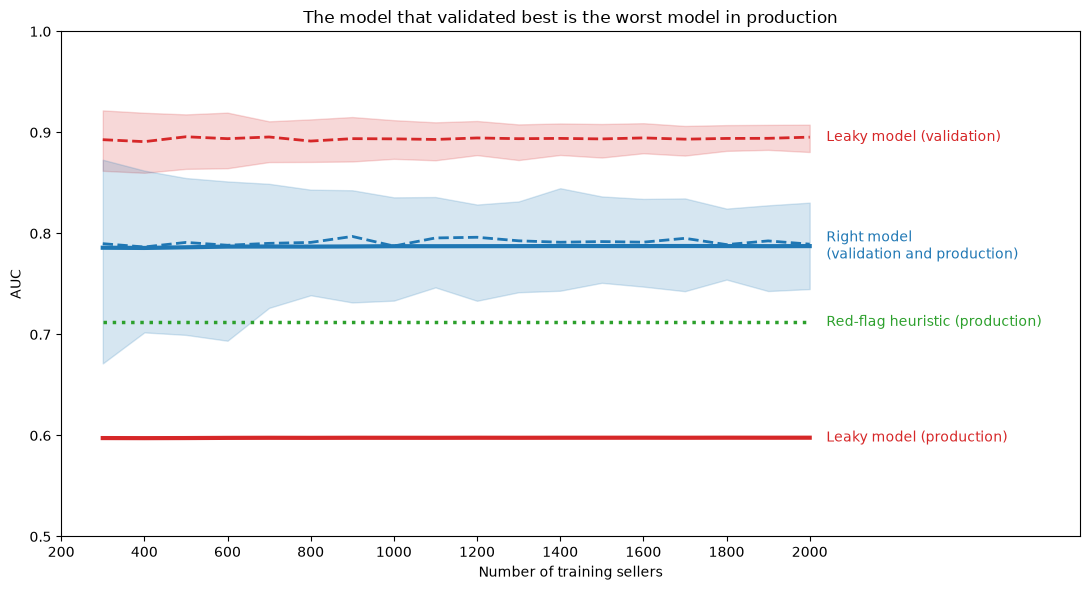

In [9]:
#Now lets consolidate the results for plotting
summary_production_test = production_test.groupby(
    ['training_size'], 
    as_index=False
).agg(
    med_leaky_auc_cv=('leaky_auc_cv', 'median'),
    med_leaky_auc_prod=('leaky_auc_prod', 'median'),
    med_right_auc_cv=('right_auc_cv', 'median'),
    med_right_auc_prod=('right_auc_prod', 'median'),
 
    iclow_leaky_auc_cv=('leaky_auc_cv', lambda x: x.quantile(0.025)),
    iclow_leaky_auc_prod=('leaky_auc_prod', lambda x: x.quantile(0.025)),
    iclow_right_auc_cv=('right_auc_cv', lambda x: x.quantile(0.025)),
    iclow_right_auc_prod=('right_auc_prod', lambda x: x.quantile(0.025)),
 
    ichigh_leaky_auc_cv=('leaky_auc_cv', lambda x: x.quantile(0.975)),
    ichigh_leaky_auc_prod=('leaky_auc_prod', lambda x: x.quantile(0.975)),
    ichigh_right_auc_cv=('right_auc_cv', lambda x: x.quantile(0.975)),
    ichigh_right_auc_prod=('right_auc_prod', lambda x: x.quantile(0.975)),
)
#print(summary_production_test)    
import matplotlib.pyplot as plt

x = summary_production_test['training_size']
fig, ax = plt.subplots(figsize=(11, 6))

# Leaky: validation with band, production line
ax.plot(x, summary_production_test['med_leaky_auc_cv'], color='C3', ls='--', lw=2)
ax.fill_between(x, summary_production_test['iclow_leaky_auc_cv'],
                   summary_production_test['ichigh_leaky_auc_cv'], color='C3', alpha=0.18)
ax.plot(x, summary_production_test['med_leaky_auc_prod'], color='C3', lw=3)

# Right: validation with band, production line
ax.plot(x, summary_production_test['med_right_auc_cv'], color='C0', ls='--', lw=2)
ax.fill_between(x, summary_production_test['iclow_right_auc_cv'],
                   summary_production_test['ichigh_right_auc_cv'], color='C0', alpha=0.18)
ax.plot(x, summary_production_test['med_right_auc_prod'], color='C0', lw=3)

ax.hlines(auc_heuristic['auc_prod'], x.min(), x.iloc[-1], color='C2', ls=':', lw=2.5)

# Direct labels at the right edge
xr = x.iloc[-1] + 40
ax.text(xr, summary_production_test['med_leaky_auc_cv'].iloc[-1],   'Leaky model (validation)', color='C3', va='center')
ax.text(xr, summary_production_test['med_right_auc_prod'].iloc[-1], 'Right model \n(validation and production)', color='C0', va='center')
ax.text(xr, auc_heuristic['auc_prod'],                              'Red-flag heuristic (production)', color='C2', va='center')
ax.text(xr, summary_production_test['med_leaky_auc_prod'].iloc[-1], 'Leaky model (production)', color='C3', va='center')

ax.set_xlim(x.min(), x.max() + 650)
ax.set_ylim(0.5, 1.0)
ax.set_xlabel('Number of training sellers'); ax.set_ylabel('AUC')
ax.set_title('The model that validated best is the worst model in production')
plt.tight_layout();
ax.set_xticks([200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000])
plt.savefig("G:/My Drive/Projects/Leakage/leakage.png",
            dpi=300, bbox_inches='tight')
plt.show()

## The Results Separate The Three Stories.

1. **Validation picked the wrong winner:** the leaky model scored about 0.89 on its random split and the right model only about 0.79 on its split by seller. Their 95% bands overlap only at the smallest training sizes (300-400 sellers).
2. **In production, the ranking reversed.** The leaky model collapsed to about 0.60, close to a coin flip, because the seller memory that inflated its validation score vanished and the seller features it dropped were never replaced.
3. **The right model delivered about 0.79, matching its validation AUC, so the split by seller was an honest estimate.** The red-flag heuristic, with no fitted parameters, landed at about 0.71, well above the leaky model and below the right model, since it uses the seller features the leaky model discarded but with equal weights and fixed cutoffs.

Most importantly, every line is flat: more training sellers narrow the validation bands but never move the leaky model toward its validation score. More data bought precision, not accuracy. The model with the best validation score is the worst model in production, and a four-rule checklist beats it.